# Tugas Praktikum
Jobsheet 9 - Klasifikasi 2 (Support Vector Machine)

**Bagian 1** — SVM pada dataset suara `voice.csv`: tiga kernel × dua rasio split.
**Bagian 2** — Klasifikasi citra siang/malam dengan SVM kernel RBF menggunakan fitur **histogram**.

---
## Bagian 1 - SVM pada Dataset `voice.csv`

**Dataset:** `voice.csv` — 3.168 sampel suara berlabel `male` / `female` dengan 20 fitur akustik (`meanfreq`, `sd`, `median`, `Q25`, `Q75`, `IQR`, `skew`, `kurt`, `sp.ent`, `sfm`, `mode`, `centroid`, `meanfun`, `minfun`, `maxfun`, `meandom`, `mindom`, `maxdom`, `dfrange`, `modindx`).

**Rancangan percobaan:**

| Faktor | Nilai |
|---|---|
| Rasio split | 70:30 dan 80:20 (*stratified*) |
| Kernel | `linear`, `poly` (derajat 3), `rbf` |
| Metrik | akurasi latih dan akurasi uji |

Fitur distandarisasi dengan `StandardScaler` karena SVM berbasis jarak dan *inner product* — tanpa standardisasi, fitur berskala besar seperti `centroid` dan `meanfreq` akan mendominasi perhitungan.

### Langkah 1 - Import Library & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set(style='whitegrid')

df = pd.read_csv('voice.csv')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### Langkah 2 - Pemeriksaan Data

In [2]:
print(df['label'].value_counts())
print()
print('Missing values:', int(df.isna().sum().sum()))
print('Duplikat     :', int(df.duplicated().sum()))

label
male      1584
female    1584
Name: count, dtype: int64

Missing values: 0
Duplikat     : 2


In [3]:
sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplikat dibuang: {sebelum - len(df)} baris -> sisa {len(df)} baris')

Duplikat dibuang: 2 baris -> sisa 3166 baris


Distribusi kelas seimbang (1.584 vs 1.584), sehingga akurasi cukup sebagai metrik utama. Baris duplikat dibuang agar tidak ada data uji yang identik dengan data latih (*data leakage*) — duplikat antar-split membuat akurasi uji terlihat lebih tinggi dari yang sebenarnya.

### Langkah 3 - Encoding Label & Fungsi Eksperimen

In [4]:
X = df.drop(columns=['label'])
y = df['label'].map({'male': 1, 'female': 0})

print('Dimensi fitur:', X.shape)
print('Proporsi kelas:', y.value_counts(normalize=True).round(3).to_dict())

Dimensi fitur: (3166, 20)
Proporsi kelas: {1: 0.5, 0: 0.5}


In [5]:
def jalankan_svm(test_size, kernel, C=1.0, degree=3, gamma='scale'):
    # Split stratified agar proporsi kelas terjaga di kedua bagian
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    # Standardisasi: fit hanya pada data latih
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    model = SVC(kernel=kernel, C=C, degree=degree, gamma=gamma)
    model.fit(X_tr_sc, y_tr)

    hasil = {
        'Rasio split': f'{int(round((1 - test_size) * 100))}:{int(round(test_size * 100))}',
        'Kernel': kernel,
        'Akurasi latih': accuracy_score(y_tr, model.predict(X_tr_sc)),
        'Akurasi uji': accuracy_score(y_te, model.predict(X_te_sc)),
        'Jumlah support vector': int(model.n_support_.sum()),
    }

    return hasil, model, (X_te_sc, y_te)

### Langkah 4 - Eksperimen Split × Kernel
Enam model dilatih: tiga kernel untuk masing-masing rasio split.

In [6]:
baris = []
model_tersimpan = {}

for test_size in [0.3, 0.2]:            # 70:30 lalu 80:20
    for kernel in ['linear', 'poly', 'rbf']:
        hasil, model, data_uji = jalankan_svm(test_size=test_size, kernel=kernel)
        baris.append(hasil)
        model_tersimpan[(test_size, kernel)] = (model, data_uji)

rekap = pd.DataFrame(baris)
rekap['Rasio split'] = pd.Categorical(rekap['Rasio split'], ['70:30', '80:20'], ordered=True)
rekap['Kernel'] = pd.Categorical(rekap['Kernel'], ['linear', 'poly', 'rbf'], ordered=True)
rekap = rekap.sort_values(['Rasio split', 'Kernel']).reset_index(drop=True)

rekap.round(4)

,Rasio split,Kernel,Akurasi latih,Akurasi uji,Jumlah support vector
0,70:30,linear,0.9761,0.9737,189
1,70:30,poly,0.9662,0.9579,608
2,70:30,rbf,0.9856,0.9811,317
3,80:20,linear,0.9759,0.9732,212
4,80:20,poly,0.9668,0.9621,673
5,80:20,rbf,0.9850,0.9826,350


### Langkah 5 - Tabulasi & Visualisasi Performansi
Tabel di atas adalah tabulasi yang diminta. Berikut versi pivot agar perbandingan antar split dan kernel lebih mudah dibaca.

In [7]:
pivot = rekap.pivot_table(index='Rasio split', columns='Kernel',
                          values='Akurasi uji', observed=True)
pivot.round(4)

Kernel,linear,poly,rbf
Rasio split,,,
70:30,0.9737,0.9579,0.9811
80:20,0.9732,0.9621,0.9826


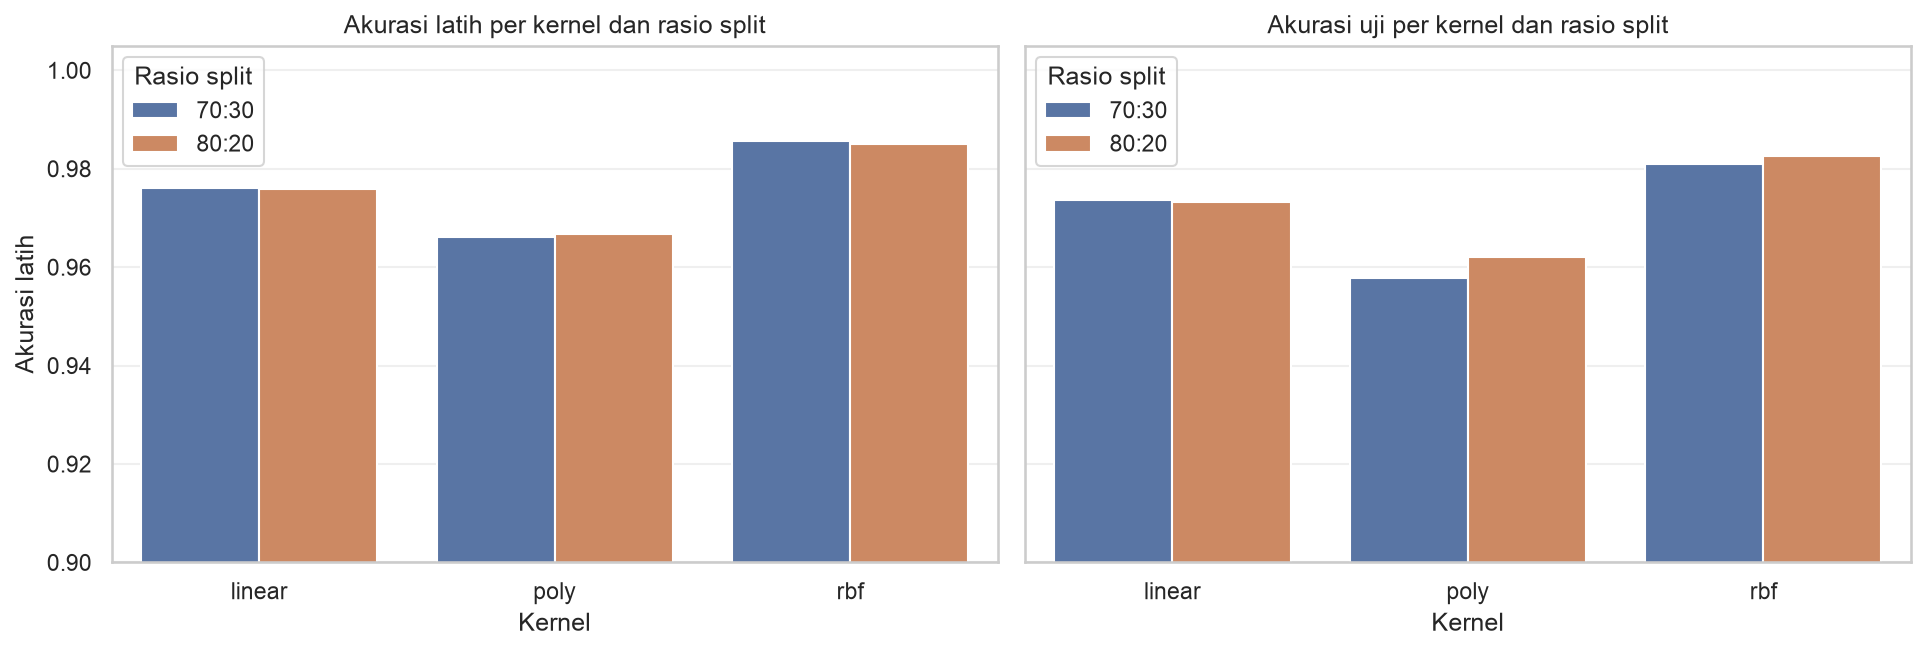

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axi, metrik in zip(ax, ['Akurasi latih', 'Akurasi uji']):
    sns.barplot(data=rekap, x='Kernel', y=metrik, hue='Rasio split', ax=axi)
    axi.set_title(f'{metrik} per kernel dan rasio split')
    axi.set_ylim(0.9, 1.005)
    axi.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Langkah 6 - Evaluasi Model Terbaik

Konfigurasi terbaik:
Rasio split                 80:20
Kernel                        rbf
Akurasi latih            0.984992
Akurasi uji               0.98265
Jumlah support vector         350

              precision    recall  f1-score   support

      female       0.98      0.98      0.98       317
        male       0.98      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



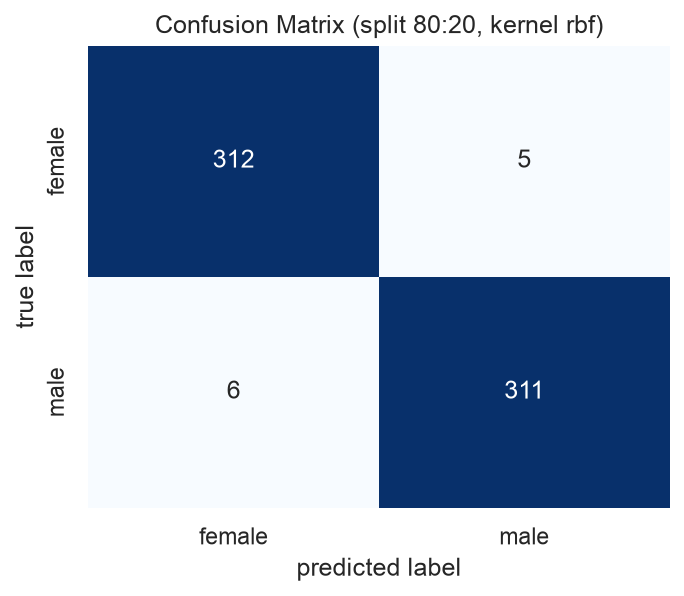

In [9]:
terbaik = rekap.sort_values('Akurasi uji', ascending=False).iloc[0]
print('Konfigurasi terbaik:')
print(terbaik.to_string())

kernel_terbaik = str(terbaik['Kernel'])
split_terbaik = 0.3 if str(terbaik['Rasio split']) == '70:30' else 0.2

model, (X_te_sc, y_te) = model_tersimpan[(split_terbaik, kernel_terbaik)]
y_pred = model.predict(X_te_sc)

print()
print(classification_report(y_te, y_pred, target_names=['female', 'male']))

mat = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(mat, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['female', 'male'], yticklabels=['female', 'male'])
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title(f'Confusion Matrix (split {terbaik["Rasio split"]}, kernel {kernel_terbaik})')
plt.show()

In [10]:
# Pengaruh C pada kernel terbaik
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=split_terbaik, random_state=42, stratify=y
)
scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)

baris_c = []
for C in [0.1, 1, 10, 100]:
    m = SVC(kernel=kernel_terbaik, C=C).fit(X_tr_sc, y_tr)
    baris_c.append({
        'C': C,
        'Akurasi latih': accuracy_score(y_tr, m.predict(X_tr_sc)),
        'Akurasi uji': accuracy_score(y_te, m.predict(X_te_sc)),
        'Jumlah support vector': int(m.n_support_.sum()),
    })

pd.DataFrame(baris_c).round(4)

,C,Akurasi latih,Akurasi uji,Jumlah support vector
0,0.1,0.9700,0.9700,761
1,1.0,0.9850,0.9826,350
2,10.0,0.9945,0.9890,229
3,100.0,1.0000,0.9842,199


### Analisis Bagian 1

* **Semua kernel memberi akurasi uji tinggi (> 0,95)**, tetapi urutannya konsisten: `rbf` (**0,9811–0,9826**) > `linear` (**0,9732–0,9737**) > `poly` (**0,9579–0,9621**).
* **Kernel RBF terbaik** karena masih mampu menangkap sedikit kelengkungan pada batas kelas, dengan jumlah support vector jauh lebih sedikit (317–350) dibanding `poly` (608–673) yang paling boros komputasi sekaligus paling tidak akurat.
* **Rasio split hampir tidak berpengaruh**: 80:20 sedikit lebih baik untuk `rbf` (0,9826 vs 0,9811), sedangkan `linear` sedikit lebih baik pada 70:30 (0,9737 vs 0,9732). Selisihnya di bawah 0,1 poin persen → model sudah stabil pada ~2.200 data latih.
* **Pengaruh `C` (pada `rbf`, split 80:20):** akurasi uji terbaik di `C=10` (**0,9890**) dengan 229 support vector. Pada `C=100`, akurasi latih mencapai **1,0000** tetapi akurasi uji **turun** menjadi 0,9842 — gejala **overfitting**: margin menyempit (hanya 199 support vector) dan model mulai menghafal data latih.
* Kesimpulan praktis: konfigurasi terbaik di antara yang diuji adalah **`rbf` + split 80:20 + `C=10`**, bukan model dengan akurasi latih tertinggi.

---
## Bagian 2 - Siang/Malam dengan Fitur Histogram + SVM (RBF)

Pada Praktikum 5, fitur yang dipakai hanya **satu angka**: rata-rata kecerahan. Informasi sebaran cahaya hilang — padahal citra malam penuh lampu dan citra siang mendung bisa punya rata-rata kecerahan yang mirip.

**Fitur histogram** menyimpan sebaran nilai kecerahan: berapa banyak piksel gelap, sedang, dan terang. Dengan **32 bin** pada kanal V, satu citra diwakili 32 fitur.

**Rancangan:**

| Faktor | Nilai |
|---|---|
| Data | seluruh `images/training` + `images/test` (400 citra) |
| Split | **80:20**, *stratified* |
| Fitur utama | histogram kanal V (HSV), 32 bin, dinormalisasi |
| Model | SVM kernel RBF |
| Tuning | `GridSearchCV` atas `C` dan `gamma` |

Folder latih dan uji bawaan digabung lebih dulu lalu di-split 80:20 secara acak agar pembagian benar-benar *stratified* dan tidak bergantung pada pembagian bawaan dataset.

## Bagian 2 - Siang/Malam dengan Fitur Histogram + SVM (RBF)

Pada Praktikum 5, fitur yang dipakai hanya **satu angka**: rata-rata kecerahan. Informasi sebaran cahaya hilang — padahal citra malam penuh lampu dan citra siang mendung bisa punya rata-rata kecerahan yang mirip.

**Fitur histogram** menyimpan sebaran nilai kecerahan: berapa banyak piksel gelap, sedang, dan terang. Dengan **32 bin** pada kanal V, satu citra diwakili 32 fitur.

**Rancangan:**

| Faktor | Nilai |
|---|---|
| Data | seluruh `images/training` + `images/test` (400 citra) |
| Split | **80:20**, *stratified* |
| Fitur utama | histogram kanal V (HSV), 32 bin, dinormalisasi |
| Model | SVM kernel RBF |
| Tuning | `GridSearchCV` atas `C` dan `gamma` |

Folder latih dan uji bawaan digabung lebih dulu lalu di-split 80:20 secara acak agar pembagian benar-benar *stratified* dan tidak bergantung pada pembagian bawaan dataset.

### Langkah 1 - Kumpulkan Path Citra

In [11]:
from pathlib import Path
import matplotlib.image as mpimg
import cv2
import time

def kumpulkan_path(*img_dirs):
    paths = []
    for d in img_dirs:
        for sub in sorted(Path(d).glob('*')):
            label = sub.name
            for file in sorted(sub.glob('*.jpg')):
                paths.append((file, label))
    return paths

semua_path = kumpulkan_path('images/training', 'images/test')

print('Total citra:', len(semua_path))
print('Sebaran label:', pd.Series([p[1] for p in semua_path]).value_counts().to_dict())

Total citra: 400
Sebaran label: {'day': 200, 'night': 200}


### Langkah 2 - Ekstraksi Fitur Histogram
Histogram dihitung **per citra** (dibaca satu per satu lalu dilepas) agar memori tetap hemat, kemudian dinormalisasi sehingga jumlah seluruh bin = 1. Normalisasi penting supaya fitur tidak bergantung pada ukuran citra.

Nilai rata-rata kecerahan juga dihitung pada lintasan yang sama, sebagai pembanding pendekatan Praktikum 5.

In [12]:
def fitur_citra(path, bins=32):
    # Baca, standardisasi ukuran, lalu ubah ke HSV
    img = mpimg.imread(path)
    img = cv2.resize(img, (1100, 600))
    img_hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    # Histogram kanal V (kecerahan) + normalisasi
    hist = cv2.calcHist([img_hsv], [2], None, [bins], [0, 256]).ravel()
    hist = hist / hist.sum()

    # Pembanding: rata-rata kecerahan (fitur tunggal ala Praktikum 5)
    avg = np.sum(img_hsv[:, :, 2]) / (img.shape[0] * img.shape[1])

    return hist.astype(np.float32), float(avg)


def buat_fitur(paths, bins=32):
    X_hist = []
    X_avg = []
    y = []
    for path, label in paths:
        hist, avg = fitur_citra(path, bins)
        X_hist.append(hist)
        X_avg.append([avg])
        y.append(1 if label == 'day' else 0)
    return np.array(X_hist), np.array(X_avg), np.array(y)

In [13]:
t0 = time.perf_counter()
X_hist, X_avg, y_semua = buat_fitur(semua_path, bins=32)
durasi = time.perf_counter() - t0

print(f'Dimensi fitur histogram: {X_hist.shape}')
print(f'Dimensi fitur rata-rata: {X_avg.shape}')
print(f'Durasi ekstraksi: {durasi:.1f} detik')

Dimensi fitur histogram: (400, 32)
Dimensi fitur rata-rata: (400, 1)
Durasi ekstraksi: 1.7 detik


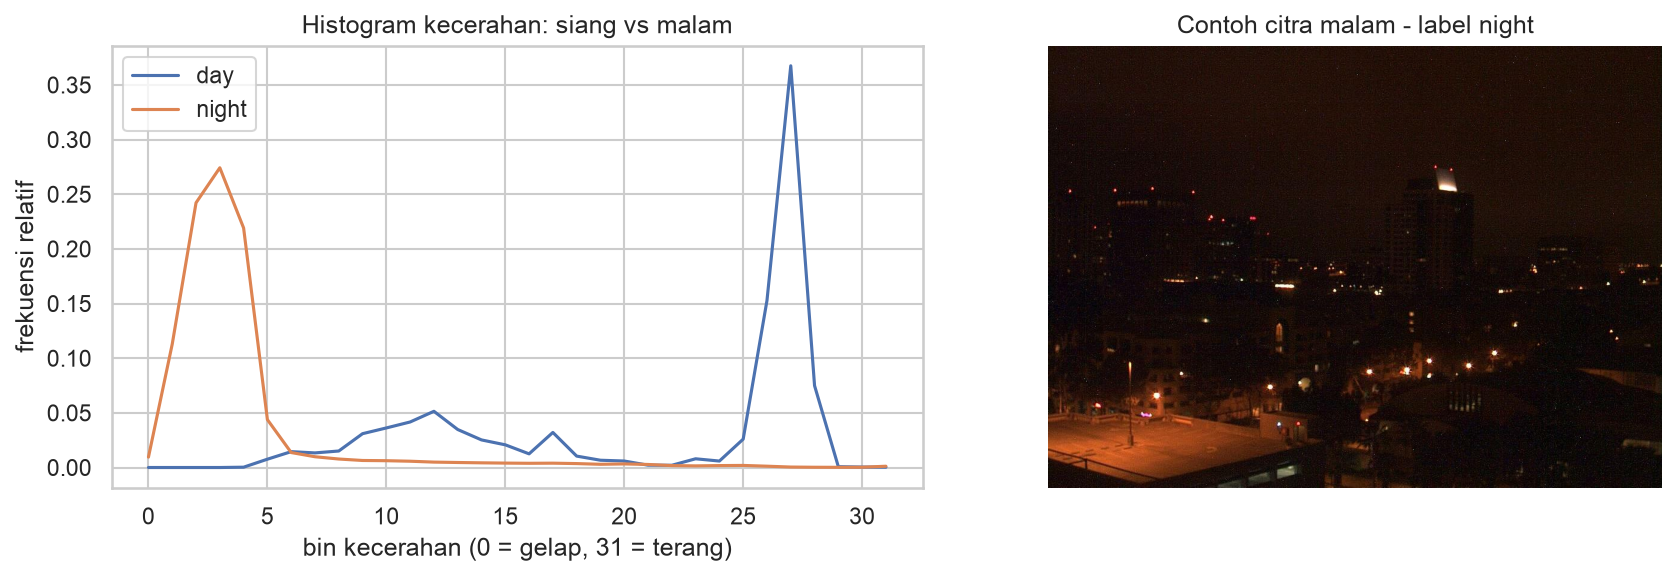

In [14]:
# Inspeksi: bandingkan histogram satu citra siang dan satu citra malam
idx_hari = np.where(y_semua == 1)[0][0]
idx_malam = np.where(y_semua == 0)[0][0]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(X_hist[idx_hari], label='day')
plt.plot(X_hist[idx_malam], label='night')
plt.xlabel('bin kecerahan (0 = gelap, 31 = terang)')
plt.ylabel('frekuensi relatif')
plt.title('Histogram kecerahan: siang vs malam')
plt.legend()

plt.subplot(1, 2, 2)
plt.imshow(mpimg.imread(semua_path[idx_malam][0]))
plt.axis('off')
plt.title(f'Contoh citra malam - label {semua_path[idx_malam][1]}')

plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV

X_tr, X_te, y_tr, y_te = train_test_split(
    X_hist, y_semua, test_size=0.2, random_state=42, stratify=y_semua
)
Xavg_tr, Xavg_te, _, _ = train_test_split(
    X_avg, y_semua, test_size=0.2, random_state=42, stratify=y_semua
)

print('Data latih:', X_tr.shape, '| Data uji:', X_te.shape)
print('Kelas latih:', dict(zip(*np.unique(y_tr, return_counts=True))))
print('Kelas uji  :', dict(zip(*np.unique(y_te, return_counts=True))))

Data latih: (320, 32) | Data uji: (80, 32)
Kelas latih: {np.int64(0): np.int64(160), np.int64(1): np.int64(160)}
Kelas uji  : {np.int64(0): np.int64(40), np.int64(1): np.int64(40)}


### Langkah 3 - Model SVM RBF + Hyperparameter Tuning
Grid yang dicoba: `C ∈ {0.1, 1, 10, 100}` dan `gamma ∈ {scale, 0.01, 0.1, 1}`, divalidasi dengan 5-fold cross-validation.

In [16]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1],
}

grid_hist = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.perf_counter()
grid_hist.fit(X_tr, y_tr)
print(f'Durasi GridSearch: {time.perf_counter() - t0:.1f} detik')
print('Parameter terbaik:', grid_hist.best_params_)
print(f'CV score terbaik : {grid_hist.best_score_:.4f}')

Durasi GridSearch: 3.9 detik
Parameter terbaik: {'C': 10, 'gamma': 'scale'}
CV score terbaik : 0.9906


In [17]:
model_hist = grid_hist.best_estimator_

acc_train_hist = accuracy_score(y_tr, model_hist.predict(X_tr))
acc_test_hist = accuracy_score(y_te, model_hist.predict(X_te))

print(f'Akurasi train (histogram): {acc_train_hist:.4f}')
print(f'Akurasi test  (histogram): {acc_test_hist:.4f}')

Akurasi train (histogram): 0.9938
Akurasi test  (histogram): 0.9875


### Langkah 4 - Evaluasi

              precision    recall  f1-score   support

       night       1.00      0.97      0.99        40
         day       0.98      1.00      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



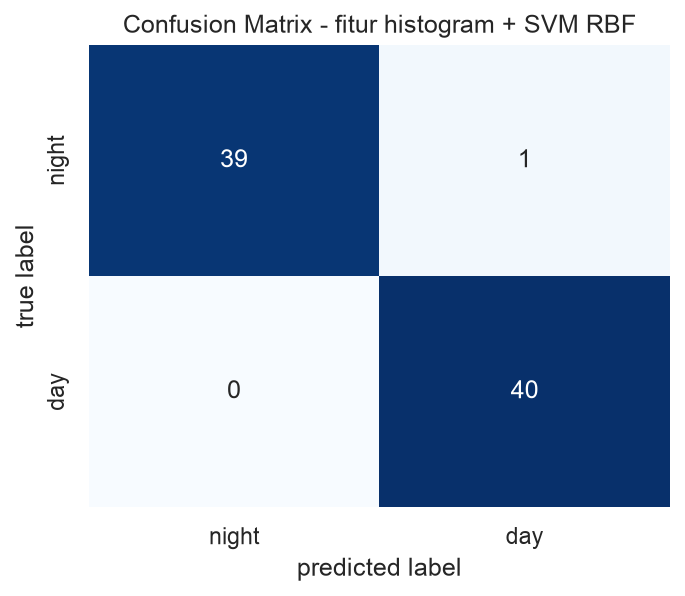

In [18]:
y_pred = model_hist.predict(X_te)

print(classification_report(y_te, y_pred, target_names=['night', 'day']))

mat = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(mat, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title('Confusion Matrix - fitur histogram + SVM RBF')
plt.show()

### Langkah 5 - Pembanding: Threshold & Fitur Rata-rata Kecerahan
Agar kesimpulan adil, kedua pembanding dievaluasi pada **split 80:20 yang sama**.

In [19]:
# (a) Threshold manual pada rata-rata kecerahan
def akurasi_threshold(X_avg, y, threshold=120):
    pred = (X_avg.ravel() > threshold).astype(int)
    return accuracy_score(y, pred)

# (b) SVM RBF dengan fitur rata-rata kecerahan, dituning serupa
grid_avg = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, n_jobs=-1, scoring='accuracy')
grid_avg.fit(Xavg_tr, y_tr)
model_avg = grid_avg.best_estimator_

perbandingan = pd.DataFrame([
    {'Pendekatan': 'Threshold rata-rata kecerahan (120)',
     'Jumlah fitur': 1,
     'Akurasi uji': akurasi_threshold(Xavg_te, y_te, 120)},
    {'Pendekatan': 'SVM RBF + rata-rata kecerahan',
     'Jumlah fitur': 1,
     'Akurasi uji': accuracy_score(y_te, model_avg.predict(Xavg_te))},
    {'Pendekatan': 'SVM RBF + histogram (tuned)',
     'Jumlah fitur': X_hist.shape[1],
     'Akurasi uji': acc_test_hist},
])

perbandingan.round(4)

,Pendekatan,Jumlah fitur,Akurasi uji
0,Threshold rata-rata kecerahan (120),1,0.8250
1,SVM RBF + rata-rata kecerahan,1,0.9000
2,SVM RBF + histogram (tuned),32,0.9875


In [20]:
# Pengaruh jumlah bin histogram (memakai hyperparameter terbaik)
baris_bin = []
for bins in [8, 16, 32, 64, 128]:
    Xb, _, yb = buat_fitur(semua_path, bins=bins)
    Xtr_b, Xte_b, ytr_b, yte_b = train_test_split(
        Xb, yb, test_size=0.2, random_state=42, stratify=yb
    )
    m = SVC(kernel='rbf', **grid_hist.best_params_).fit(Xtr_b, ytr_b)
    baris_bin.append({
        'Jumlah bin': bins,
        'Akurasi latih': accuracy_score(ytr_b, m.predict(Xtr_b)),
        'Akurasi uji': accuracy_score(yte_b, m.predict(Xte_b)),
    })

rekap_bin = pd.DataFrame(baris_bin)
rekap_bin.round(4)

,Jumlah bin,Akurasi latih,Akurasi uji
0,8,0.9844,0.9875
1,16,0.9938,0.9875
2,32,0.9938,0.9875
3,64,0.9969,0.9875
4,128,0.9938,0.9875


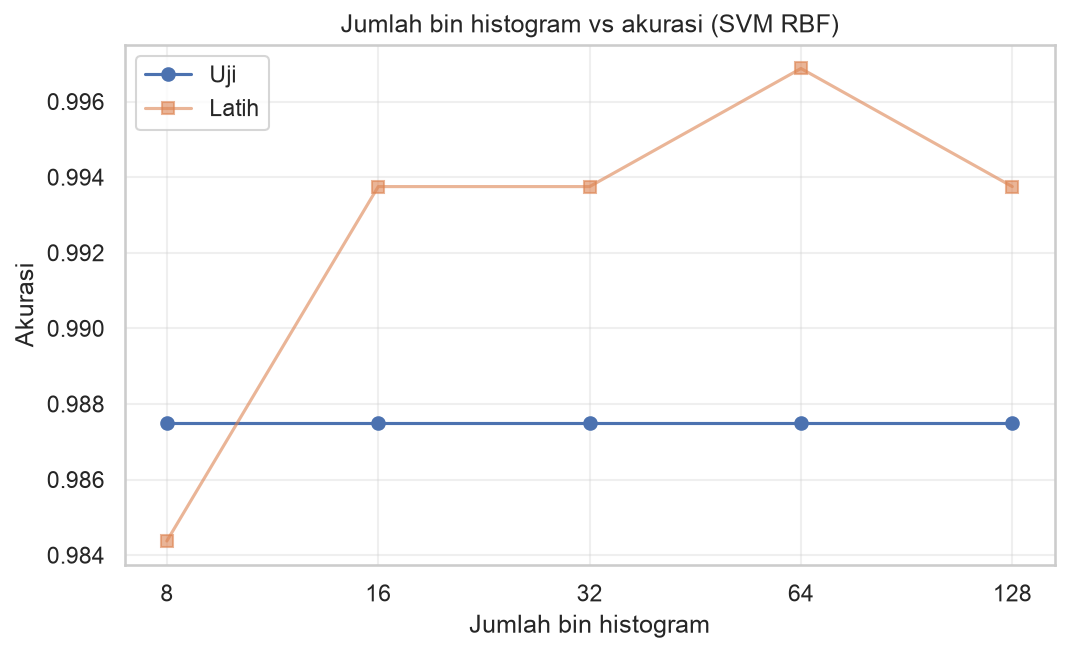

In [21]:
plt.figure(figsize=(8, 4.5))
plt.plot(rekap_bin['Jumlah bin'], rekap_bin['Akurasi uji'], marker='o', label='Uji')
plt.plot(rekap_bin['Jumlah bin'], rekap_bin['Akurasi latih'], marker='s', label='Latih', alpha=0.6)
plt.xscale('log', base=2)
plt.xticks(rekap_bin['Jumlah bin'], rekap_bin['Jumlah bin'])
plt.xlabel('Jumlah bin histogram')
plt.ylabel('Akurasi')
plt.title('Jumlah bin histogram vs akurasi (SVM RBF)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Analisis Bagian 2

* **Histogram jauh lebih unggul** pada split 80:20 yang sama: threshold manual **0,8250**, SVM dengan rata-rata kecerahan **0,9000**, dan SVM dengan histogram 32 bin (setelah tuning) **0,9875**. Kesalahan turun dari 14 citra menjadi hanya 1 citra dari 80.
* Sebabnya, histogram menyimpan **bentuk** sebaran cahaya, bukan hanya pusatnya — citra malam yang penuh lampu tidak lagi tertukar dengan citra siang yang redup.
* Tuning memilih `C=10` dan `gamma='scale'` (CV 0,9906). Akurasi latih 0,9938 dan akurasi uji 0,9875 — selisihnya kecil, jadi **tidak overfitting**.
* **Jumlah bin hampir tidak berpengaruh pada dataset ini**: 8 sampai 128 bin semuanya memberi akurasi uji **0,9875**. Perbedaan kecerdasan siang–malam terlalu besar untuk gagal dipisahkan oleh histogram kasar. Namun akurasi latih naik seiring bertambahnya bin (0,9844 pada 8 bin → 0,9969 pada 64 bin), tanda bahwa bin sangat banyak mulai **menghafal** detail data latih. Pada dataset yang lebih sulit, jumlah bin akan jauh lebih menentukan.
* **`gamma`** menentukan lebar pengaruh tiap titik: nilai besar membuat batas keputusan sangat tajam (rawan overfitting), nilai kecil terlalu halus (underfitting); **`C`** mengatur toleransi pelanggaran margin.
* Pelajaran utama: **kualitas representasi fitur lebih menentukan daripada pilihan classifier**. SVM hanya sebaik fitur yang diberikannya.

### Catatan Metodologis

* `StandardScaler` hanya di-*fit* pada data latih, lalu dipakai untuk men-*transform* data uji.
* Duplikat pada `voice.csv` dibuang agar tidak terjadi kebocoran latih → uji.
* `stratify=y` dipakai di semua split agar proporsi kelas pada data uji mencerminkan populasi.
* Data citra digabung lalu di-split 80:20 secara acak, sesuai permintaan tugas — bukan memakai pembagian folder bawaan.
* Fitur histogram dinormalisasi (jumlah bin = 1) agar tidak bergantung pada ukuran citra; `GridSearchCV` memakai 5-fold cross-validation pada data latih saja.